In [1]:
#question 1.1

import pandas as pd
import re


df = pd.read_json("research_abstracts.json")

#data inspection
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

#data cleaning
df = df.dropna(subset=["Abstract", "Label"]).drop_duplicates()
df["Label"] = df["Label"].str.strip().str.lower()

#text denoising
def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"http\S+|www\S+", " ", text) # URLs
    text = re.sub(r"\S+@\S+", " ", text)        # email addresses
    text = re.sub(r"\d+", " ", text)            # numbers
    text = re.sub(r"[^a-z\s]", " ", text)       # punctuation/symbols
    text = re.sub(r"\s+", " ", text).strip()    # extra spaces
    return text

#apply text denoising
df["Clean_Abstract"] = df["Abstract"].apply(clean_text)

#display
print("\nClass distribution:")
print(df["Label"].value_counts())

display(df[["Abstract", "Clean_Abstract", "Label"]].head())

Dataset shape: (1138, 3)

Missing values:
DOI         4
Abstract    0
Label       0
dtype: int64

Duplicates: 2

Class distribution:
Label
classical    900
ai           236
Name: count, dtype: int64


,Abstract,Clean_Abstract,Label
0,Forward-looking forecasting of the inflation r...,forward looking forecasting of the inflation r...,ai
1,Our study examined the disaggregation of infla...,our study examined the disaggregation of infla...,ai
2,This paper develops a dynamic factor model tha...,this paper develops a dynamic factor model tha...,classical
3,"In this paper, I use a simple SIR Macro model ...",in this paper i use a simple sir macro model t...,classical
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory is useful for identifyin...,classical


In [4]:
#question 1.2
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["Clean_Abstract"]   # Predictor
y = df["Label"]            # Target

#text to numerical features using TF-IDF
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

X_tfidf = tfidf.fit_transform(X)

#display
print("Number of documents:", X_tfidf.shape[0])
print("Number of features:", X_tfidf.shape[1])

print("\nSample TF-IDF features:")
print(tfidf.get_feature_names_out()[:30])

Number of documents: 1136
Number of features: 5000

Sample TF-IDF features:
['ability' 'ability predict' 'able' 'able predict' 'absence' 'absenteeism'
 'absolute' 'absolute error' 'absolute percentage' 'abstract' 'abundant'
 'academic' 'accelerated' 'accepted' 'access' 'accommodate' 'accompanied'
 'accord' 'accordance' 'according' 'accordingly' 'account' 'accounted'
 'accounting' 'accounts' 'accumulation' 'accumulative' 'accuracies'
 'accuracy' 'accuracy forecasts']


Training samples: 908
Testing samples: 228

Training Accuracy: 0.9769
Testing Accuracy: 0.8904
Generalisation Gap: 0.0865

Classification Report:

              precision    recall  f1-score   support

          ai      0.704     0.809     0.752        47
   classical      0.948     0.912     0.930       181

    accuracy                          0.890       228
   macro avg      0.826     0.860     0.841       228
weighted avg      0.898     0.890     0.893       228



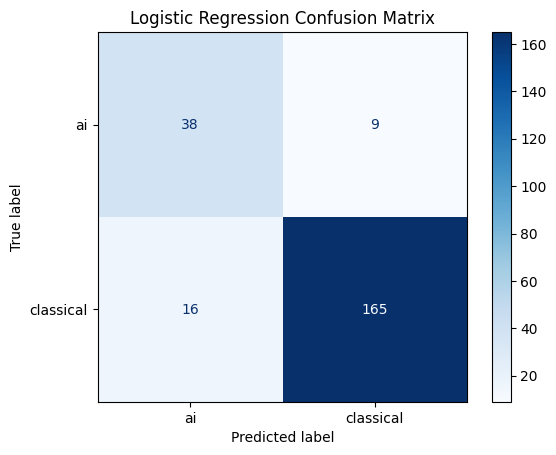

In [5]:
#question 1.3
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


#training and testing sets split
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


#build and train baseline model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)


#predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


#compare training and testing accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\nTraining Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))
print(
    "Generalisation Gap:",
    round(train_accuracy - test_accuracy, 4)
)


#classification performance report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        digits=3
    )
)


#confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [6]:
#question 2.1

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


#predictor and target
X = df["Clean_Abstract"]
y = df["Label"]


#one consistent train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


#the four models
models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVC": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SGD Classifier": SGDClassifier(
        loss="modified_huber",
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
}


#train and evaluate each model
results = []
trained_models = {}

for model_name, classifier in models.items():

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2),
                max_features=5000,
                sublinear_tf=True
            )
        ),
        ("classifier", classifier)
    ])

    #train model
    pipeline.fit(X_train, y_train)

    #save complete fitted pipeline
    trained_models[model_name] = pipeline

    #predictions
    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    #performance measures
    train_accuracy = accuracy_score(
        y_train,
        train_predictions
    )

    test_accuracy = accuracy_score(
        y_test,
        test_predictions
    )

    macro_f1 = f1_score(
        y_test,
        test_predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test,
        test_predictions,
        average="weighted"
    )

    ai_precision = precision_score(
        y_test,
        test_predictions,
        pos_label="ai"
    )

    ai_recall = recall_score(
        y_test,
        test_predictions,
        pos_label="ai"
    )

    ai_f1 = f1_score(
        y_test,
        test_predictions,
        pos_label="ai"
    )

    results.append({
        "Model": model_name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Generalisation Gap": train_accuracy - test_accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "AI Precision": ai_precision,
        "AI Recall": ai_recall,
        "AI F1": ai_f1
    })

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            test_predictions,
            digits=3,
            zero_division=0
        )
    )


#model comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

numeric_columns = results_df.select_dtypes(
    include="number"
).columns

results_df[numeric_columns] = (
    results_df[numeric_columns].round(4)
)

print("\nModel comparison:")
display(results_df)

Training samples: 908
Testing samples: 228

Multinomial Naive Bayes
              precision    recall  f1-score   support

          ai      1.000     0.234     0.379        47
   classical      0.834     1.000     0.910       181

    accuracy                          0.842       228
   macro avg      0.917     0.617     0.644       228
weighted avg      0.868     0.842     0.800       228


Linear SVC
              precision    recall  f1-score   support

          ai      0.850     0.723     0.782        47
   classical      0.931     0.967     0.949       181

    accuracy                          0.917       228
   macro avg      0.890     0.845     0.865       228
weighted avg      0.914     0.917     0.914       228


Random Forest
              precision    recall  f1-score   support

          ai      0.850     0.723     0.782        47
   classical      0.931     0.967     0.949       181

    accuracy                          0.917       228
   macro avg      0.890     0.845

,Model,Training Accuracy,Testing Accuracy,Generalisation Gap,Macro F1,Weighted F1,AI Precision,AI Recall,AI F1
0,SGD Classifier,1.0000,0.9123,0.0877,0.8660,0.9123,0.7872,0.7872,0.7872
1,Linear SVC,0.9989,0.9167,0.0822,0.8651,0.9141,0.8500,0.7234,0.7816
2,Random Forest,1.0000,0.9167,0.0833,0.8651,0.9141,0.8500,0.7234,0.7816
3,Multinomial Naive Bayes,0.9053,0.8421,0.0632,0.6444,0.8002,1.0000,0.2340,0.3793
